Enter amplitude alpha:  0.8
Enter amplitude beta:  0.6



ORIGINAL QUANTUM STATE:
((0.8+0j))|0> + ((0.6+0j))|1>

ERROR CONFIGURATION
Enter a qubit number from 0 to 8.
Press Enter if you do not want that error.



Enter X error qubit (0-8, Enter for none):  2
Enter Z error qubit (0-8, Enter for none):  6



SELECTED ERRORS:
X error: q[2]
Z error: q[6]

STAGE 1: ENCODED QUANTUM STATE
Basis states are displayed in q8...q0 order:

(+0.4950) |000000000>
(+0.0707) |000000111>
(+0.0707) |000111000>
(+0.4950) |000111111>
(+0.0707) |111000000>
(+0.4950) |111000111>
(+0.4950) |111111000>
(+0.0707) |111111111>

ERROR INJECTION COMPLETED.
X error introduced on q[2].
Z error introduced on q[6].


C:\Users\pvsr\AppData\Local\Temp\ipykernel_14564\3371800180.py:128: DeprecationWarning: The return type of saved statevectors has been changed from a `numpy.ndarray` to a `qiskit.quantum_info.Statevector` as of qiskit-aer 0.10. Accessing numpy array attributes is deprecated and will result in an error in a future release. To continue using saved result objects as arrays you can explicitly cast them using  `np.asarray(object)`.
  for index, amplitude in enumerate(state):



STAGE 2: QUANTUM STATE AFTER ERROR INJECTION
Basis states are displayed in q8...q0 order:

(+0.0707) |000000011>
(+0.4950) |000000100>
(+0.4950) |000111011>
(+0.0707) |000111100>
(-0.4950) |111000011>
(-0.0707) |111000100>
(-0.0707) |111111011>
(-0.4950) |111111100>

             SYNDROME RESULTS

Measured syndrome counts:
{'10 00 00 10': 1}

Expected bit-flip syndromes:
Block 1 (s0): 10
Block 2 (s1): 00
Block 3 (s2): 00

Expected phase-flip syndrome (p): 10

          ERROR CORRECTION

X error detected at q[2].
Correction: X applied to q[2].

Z error detected at q[6].
Correction: Z applied to q[6].
This corrects the equivalent phase error in the same Shor block.

             SHOR CODE RESULTS

Original quantum state:
(+0.8000)|0> + (+0.6000)|1>

Recovered quantum state:
(+0.8000)|0> + (+0.6000)|1>

Fidelity: 1.0

QUANTUM ERROR CORRECTION SUCCESSFUL!
Original quantum state recovered.


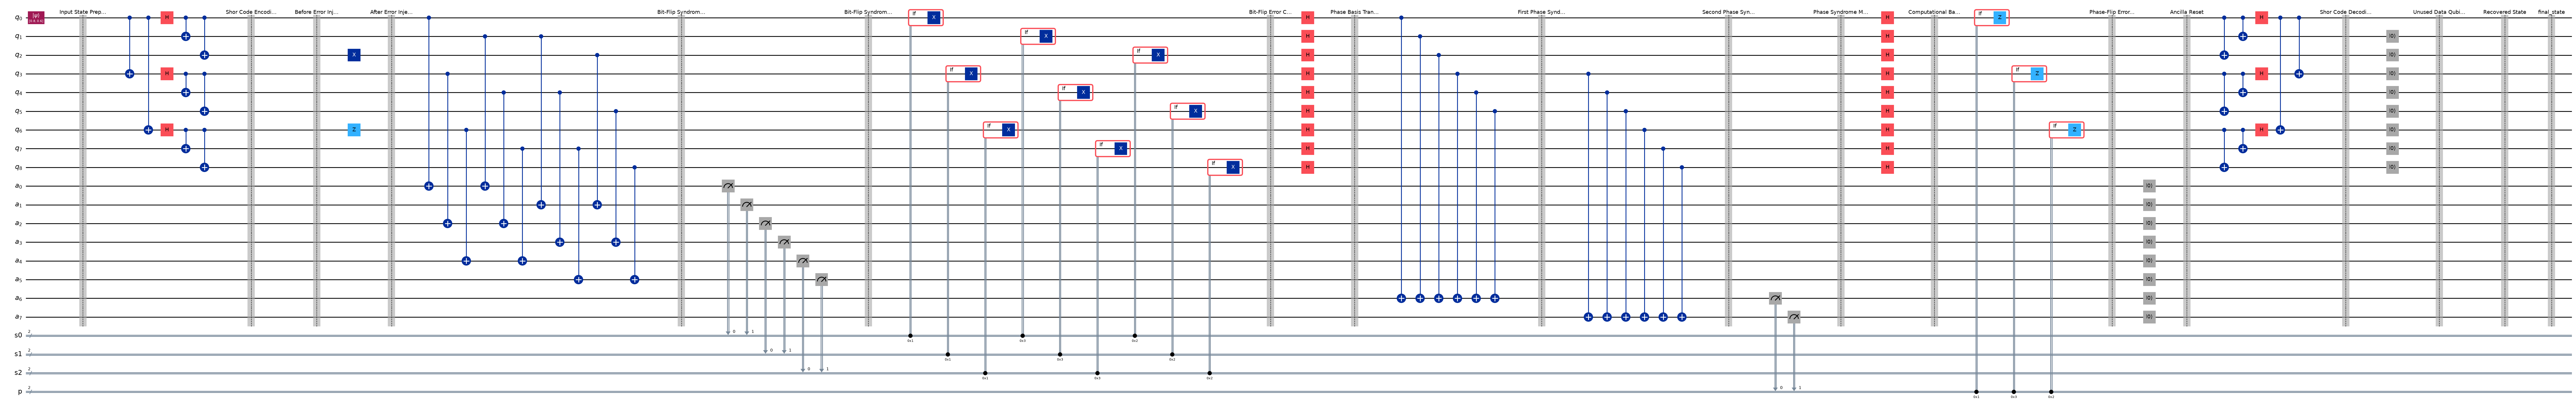

In [11]:

import numpy as np
import matplotlib.pyplot as plt

from qiskit import (
    QuantumCircuit,
    QuantumRegister,
    ClassicalRegister,
    transpile
)

from qiskit_aer import AerSimulator
from IPython.display import display


# ==========================================
# 1. INPUT QUANTUM STATE
# ==========================================

alpha = complex(input("Enter amplitude alpha: "))
beta = complex(input("Enter amplitude beta: "))

norm = np.sqrt(abs(alpha)**2 + abs(beta)**2)

if np.isclose(norm, 0):
    raise ValueError("Input state cannot have both amplitudes zero.")

alpha = alpha / norm
beta = beta / norm

print("\nORIGINAL QUANTUM STATE:")
print(f"({alpha})|0> + ({beta})|1>")


# ==========================================
# 2. USER ERROR INPUT
# ==========================================

def get_error_input(prompt):

    value = input(prompt).strip()

    # Blank input means no error
    if value == "":
        return None

    try:
        qubit = int(value)
    except ValueError:
        raise ValueError("Enter a qubit number from 0 to 8 or press Enter.")

    if qubit not in range(9):
        raise ValueError("Qubit number must be between 0 and 8.")

    return qubit


print("\nERROR CONFIGURATION")
print("Enter a qubit number from 0 to 8.")
print("Press Enter if you do not want that error.")

x_error = get_error_input(
    "\nEnter X error qubit (0-8, Enter for none): "
)

z_error = get_error_input(
    "Enter Z error qubit (0-8, Enter for none): "
)

print("\nSELECTED ERRORS:")

if x_error is None:
    print("X error: None")
else:
    print(f"X error: q[{x_error}]")

if z_error is None:
    print("Z error: None")
else:
    print(f"Z error: q[{z_error}]")


# ==========================================
# 3. QUANTUM AND CLASSICAL REGISTERS
# ==========================================

q = QuantumRegister(9, 'q')
a = QuantumRegister(8, 'a')

s0 = ClassicalRegister(2, 's0')
s1 = ClassicalRegister(2, 's1')
s2 = ClassicalRegister(2, 's2')

p = ClassicalRegister(2, 'p')

qc = QuantumCircuit(q, a, s0, s1, s2, p)

backend = AerSimulator(method='statevector')


# ==========================================
# 4. HELPER FUNCTIONS
# ==========================================

def format_amplitude(value):

    real = value.real
    imag = value.imag

    if abs(imag) < 1e-8:
        return f"{real:+.4f}"

    if abs(real) < 1e-8:
        return f"{imag:+.4f}j"

    sign = "+" if imag >= 0 else "-"

    return f"{real:+.4f} {sign} {abs(imag):.4f}j"


def print_sparse_state(title, state):

    print("\n" + "=" * 55)
    print(title)
    print("=" * 55)

    print("Basis states are displayed in q8...q0 order:\n")

    for index, amplitude in enumerate(state):

        if abs(amplitude) > 1e-8:

            # Extract the nine data-qubit bits.
            # Ancillas are zero at these two stages.
            bits = format(index & 0b111111111, '09b')

            print(
                f"({format_amplitude(amplitude)}) "
                f"|{bits}>"
            )


def get_snapshot(circuit, label):

    # Create a separate copy so snapshots do not
    # add extra save operations to the displayed circuit.

    probe = circuit.copy()

    probe.save_statevector(label=label)

    compiled_probe = transpile(
        probe,
        backend,
        optimization_level=0
    )

    snapshot_result = backend.run(
        compiled_probe,
        shots=1
    ).result()

    return snapshot_result.data(0)[label]


# ==========================================
# 5. INPUT STATE PREPARATION
# ==========================================

qc.initialize([alpha, beta], q[0])

qc.barrier(label="Input State Preparation")


# ==========================================
# 6. SHOR CODE ENCODING
# ==========================================

# Spread logical information across three blocks

qc.cx(q[0], q[3])
qc.cx(q[0], q[6])

# Phase-flip protection

qc.h(q[0])
qc.h(q[3])
qc.h(q[6])

# Bit-flip protection

qc.cx(q[0], q[1])
qc.cx(q[0], q[2])

qc.cx(q[3], q[4])
qc.cx(q[3], q[5])

qc.cx(q[6], q[7])
qc.cx(q[6], q[8])

qc.barrier(label="Shor Code Encoding")


# Save encoded state separately for visualization

encoded_state = get_snapshot(
    qc,
    "encoded_state"
)

print_sparse_state(
    "STAGE 1: ENCODED QUANTUM STATE",
    encoded_state
)


# ==========================================
# 7. ERROR INJECTION
# ==========================================

# Both X and Z errors are placed between
# the SAME two barriers.

qc.barrier(label="Before Error Injection")

# Apply X error if selected

if x_error is not None:
    qc.x(q[x_error])

# Apply Z error if selected

if z_error is not None:
    qc.z(q[z_error])

qc.barrier(label="After Error Injection")


print("\nERROR INJECTION COMPLETED.")

if x_error is None and z_error is None:
    print("No error was introduced.")

elif x_error is not None and z_error is None:
    print(f"Bit-flip error introduced on q[{x_error}].")

elif x_error is None and z_error is not None:
    print(f"Phase-flip error introduced on q[{z_error}].")

else:
    print(f"X error introduced on q[{x_error}].")
    print(f"Z error introduced on q[{z_error}].")

    if x_error == z_error:
        print("Both errors act on the same physical qubit.")
        print("Together they are equivalent to a Y error up to global phase.")


# Save state immediately after error injection

error_state = get_snapshot(
    qc,
    "error_state"
)

print_sparse_state(
    "STAGE 2: QUANTUM STATE AFTER ERROR INJECTION",
    error_state
)


# ==========================================
# 8. BIT-FLIP SYNDROME EXTRACTION
# ==========================================

# Block 1

qc.cx(q[0], a[0])
qc.cx(q[1], a[0])

qc.cx(q[1], a[1])
qc.cx(q[2], a[1])

# Block 2

qc.cx(q[3], a[2])
qc.cx(q[4], a[2])

qc.cx(q[4], a[3])
qc.cx(q[5], a[3])

# Block 3

qc.cx(q[6], a[4])
qc.cx(q[7], a[4])

qc.cx(q[7], a[5])
qc.cx(q[8], a[5])

qc.barrier(label="Bit-Flip Syndrome Extraction")


# ==========================================
# 9. BIT-FLIP SYNDROME MEASUREMENT
# ==========================================

qc.measure(a[0], s0[0])
qc.measure(a[1], s0[1])

qc.measure(a[2], s1[0])
qc.measure(a[3], s1[1])

qc.measure(a[4], s2[0])
qc.measure(a[5], s2[1])

qc.barrier(label="Bit-Flip Syndrome Measurement")


# ==========================================
# 10. BIT-FLIP ERROR CORRECTION
# ==========================================

# Block 1

with qc.if_test((s0, 1)):
    qc.x(q[0])

with qc.if_test((s0, 3)):
    qc.x(q[1])

with qc.if_test((s0, 2)):
    qc.x(q[2])

# Block 2

with qc.if_test((s1, 1)):
    qc.x(q[3])

with qc.if_test((s1, 3)):
    qc.x(q[4])

with qc.if_test((s1, 2)):
    qc.x(q[5])

# Block 3

with qc.if_test((s2, 1)):
    qc.x(q[6])

with qc.if_test((s2, 3)):
    qc.x(q[7])

with qc.if_test((s2, 2)):
    qc.x(q[8])

qc.barrier(label="Bit-Flip Error Correction")


# ==========================================
# 11. PHASE-FLIP SYNDROME EXTRACTION
# ==========================================

# Convert all data qubits to Hadamard basis

for i in range(9):
    qc.h(q[i])

qc.barrier(label="Phase Basis Transformation")


# First phase stabilizer: X0 X1 X2 X3 X4 X5

for i in range(6):
    qc.cx(q[i], a[6])

qc.barrier(label="First Phase Syndrome Extraction")


# Second phase stabilizer: X3 X4 X5 X6 X7 X8

for i in range(3, 9):
    qc.cx(q[i], a[7])

qc.barrier(label="Second Phase Syndrome Extraction")


# ==========================================
# 12. PHASE-FLIP SYNDROME MEASUREMENT
# ==========================================

qc.measure(a[6], p[0])
qc.measure(a[7], p[1])

qc.barrier(label="Phase Syndrome Measurement")


# ==========================================
# 13. RETURN TO ORIGINAL BASIS
# ==========================================

for i in range(9):
    qc.h(q[i])

qc.barrier(label="Computational Basis Restoration")


# ==========================================
# 14. PHASE-FLIP ERROR CORRECTION
# ==========================================

# Block 1

with qc.if_test((p, 1)):
    qc.z(q[0])

# Block 2

with qc.if_test((p, 3)):
    qc.z(q[3])

# Block 3

with qc.if_test((p, 2)):
    qc.z(q[6])

qc.barrier(label="Phase-Flip Error Correction")


# ==========================================
# 15. RESET ANCILLA QUBITS
# ==========================================

for i in range(8):
    qc.reset(a[i])

qc.barrier(label="Ancilla Reset")


# ==========================================
# 16. SHOR CODE DECODING
# ==========================================

# Reverse bit-flip encoding

qc.cx(q[6], q[8])
qc.cx(q[6], q[7])

qc.cx(q[3], q[5])
qc.cx(q[3], q[4])

qc.cx(q[0], q[2])
qc.cx(q[0], q[1])

# Reverse Hadamard operations

qc.h(q[6])
qc.h(q[3])
qc.h(q[0])

# Reverse initial spreading operations

qc.cx(q[0], q[6])
qc.cx(q[0], q[3])

qc.barrier(label="Shor Code Decoding")

for i in range(1, 9):
    qc.reset(q[i])

qc.barrier(label="Unused Data Qubits Reset")
# ==========================================
# 17. SAVE FINAL STATEVECTOR
# ==========================================

qc.barrier(label="Recovered State")

qc.save_statevector(label="final_state")


# ==========================================
# 18. QUANTUM SIMULATION
# ==========================================

compiled_circuit = transpile(
    qc,
    backend,
    optimization_level=0
)

result = backend.run(
    compiled_circuit,
    shots=1
).result()

final_state = result.data(0)["final_state"]

counts = result.get_counts()


# ==========================================
# 19. DISPLAY SYNDROME INFORMATION
# ==========================================

# Local qubit syndrome mapping:
# q0 -> 01
# q1 -> 11
# q2 -> 10

local_syndrome = {
    0: 1,
    1: 3,
    2: 2
}

# Expected bit-flip syndromes

expected_bit = [0, 0, 0]

if x_error is not None:

    block = x_error // 3
    local_position = x_error % 3

    expected_bit[block] = local_syndrome[local_position]


# Expected phase-flip syndrome

expected_phase = 0

if z_error is not None:

    block = z_error // 3

    # Block 1 -> 01
    # Block 2 -> 11
    # Block 3 -> 10

    expected_phase = {
        0: 1,
        1: 3,
        2: 2
    }[block]


print("\n==========================================")
print("             SYNDROME RESULTS")
print("==========================================")

print("\nMeasured syndrome counts:")
print(counts)

print("\nExpected bit-flip syndromes:")

for i, value in enumerate(expected_bit):
    print(
        f"Block {i+1} (s{i}): "
        f"{format(value, '02b')}"
    )

print(
    "\nExpected phase-flip syndrome (p):",
    format(expected_phase, '02b')
)


# ==========================================
# 20. EXPLAIN ERROR CORRECTION
# ==========================================

print("\n==========================================")
print("          ERROR CORRECTION")
print("==========================================")

if x_error is None:
    print("\nNo bit-flip component detected.")
else:
    print(f"\nX error detected at q[{x_error}].")
    print(f"Correction: X applied to q[{x_error}].")

if z_error is None:
    print("\nNo phase-flip component detected.")
else:
    phase_block = z_error // 3
    correction_qubit = phase_block * 3

    print(f"\nZ error detected at q[{z_error}].")

    print(
        f"Correction: Z applied to q[{correction_qubit}]."
    )

    print(
        "This corrects the equivalent phase error "
        "in the same Shor block."
    )

if x_error is None and z_error is None:
    print("\nThe original state was not disturbed.")


# ==========================================
# 21. EXTRACT RECOVERED AMPLITUDES
# ==========================================

# Qiskit uses little-endian qubit ordering.
# After decoding, q0 contains the recovered state.
# All other data and ancilla qubits should be zero.

alpha_out = final_state.data[0]
beta_out = final_state.data[1]

# Normalize recovered amplitudes

norm_out = np.sqrt(
    abs(alpha_out)**2 + abs(beta_out)**2
)

if np.isclose(norm_out, 0):
    raise RuntimeError("Could not extract recovered state.")

alpha_out /= norm_out
beta_out /= norm_out


# ==========================================
# 22. FIDELITY CALCULATION
# ==========================================

overlap = np.vdot(
    [alpha, beta],
    [alpha_out, beta_out]
)

fidelity = abs(overlap)**2

# Align global phase for a clearer comparison

if abs(overlap) > 1e-12:

    phase = np.exp(-1j * np.angle(overlap))

    alpha_display = alpha_out * phase
    beta_display = beta_out * phase

else:

    alpha_display = alpha_out
    beta_display = beta_out


# ==========================================
# 23. DISPLAY FINAL RESULTS
# ==========================================

print("\n==========================================")
print("             SHOR CODE RESULTS")
print("==========================================")

print("\nOriginal quantum state:")

print(
    f"({format_amplitude(alpha)})|0> + "
    f"({format_amplitude(beta)})|1>"
)

print("\nRecovered quantum state:")

print(
    f"({format_amplitude(alpha_display)})|0> + "
    f"({format_amplitude(beta_display)})|1>"
)

print("\nFidelity:", round(fidelity, 8))

if np.isclose(fidelity, 1.0, atol=1e-6):

    print("\nQUANTUM ERROR CORRECTION SUCCESSFUL!")
    print("Original quantum state recovered.")

else:

    print("\nQUANTUM ERROR CORRECTION FAILED.")


# ==========================================
# 24. DRAW QUANTUM CIRCUIT
# ==========================================

fig = qc.draw(
    output='mpl',
    fold=-1,
    idle_wires=False,
    style={
        'backgroundcolor': 'white'
    }
)

display(fig)

plt.close(fig)


In [12]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("3_3_Shor9Bit_BitFlip_PhaseFlip.png", dpi=300, bbox_inches="tight")